In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import zscore
data={
    "Student":["A","B","C","D","E","F","G","H","I","J","K","L","M","N","O"],
    "Study_Hours":[2,3,4,5,4,6,5,3,4,5,6,4,5,30,3]
}
df=pd.DataFrame(data)
print("Original Dataset")
display(df)

Original Dataset


,Student,Study_Hours
0,A,2
1,B,3
2,C,4
3,D,5
4,E,4
5,F,6
6,G,5
7,H,3
8,I,4
9,J,5


In [ ]:
df["Study_Hours"].describe()

,Study_Hours
count,15.000000
mean,5.933333
std,6.755597
min,2.000000
25%,3.500000
50%,4.000000
75%,5.000000
max,30.000000


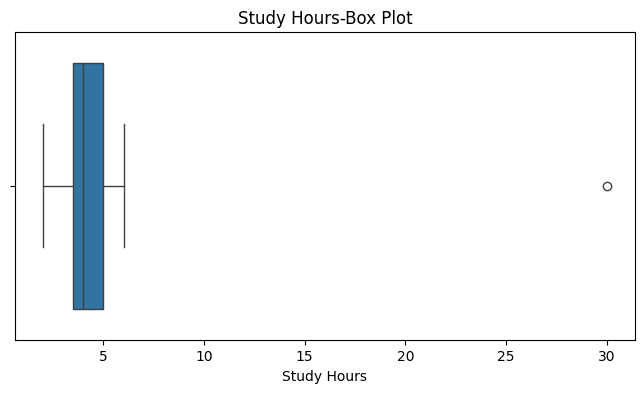

In [ ]:
plt.figure(figsize=(8,4))
sns.boxplot(x=df["Study_Hours"])
plt.title("Study Hours-Box Plot")
plt.xlabel(("Study Hours"))
plt.show()

In [ ]:
Q1=df["Study_Hours"].quantile(0.25)
Q3=df["Study_Hours"].quantile(0.75)
print("Q1:",Q1)
print("Q3:",Q3)

Q1: 3.5
Q3: 5.0


In [ ]:
IQR=Q3-Q1
print("IQR:",IQR)

IQR: 1.5


In [ ]:
lower_bound=Q1-1.5*IQR
upper_bound=Q3+1.5*IQR
print("Lower Bound:",lower_bound)
print("Upper Bound:",upper_bound)

Lower Bound: 1.25
Upper Bound: 7.25


In [ ]:
outliers_iqr=df[
    (df["Study_Hours"] < lower_bound)|
(df["Study_Hours"] > upper_bound)]
print("IQR outliers")
display(outliers_iqr)


IQR outliers


,Student,Study_Hours
13,N,30


In [ ]:
normal_data_iqr=df[
    (df["Study_Hours"] >= lower_bound)&
(df["Study_Hours"] <= upper_bound)]
print("IQR outliers")
display(normal_data_iqr)



IQR outliers


,Student,Study_Hours
0,A,2
1,B,3
2,C,4
3,D,5
4,E,4
5,F,6
6,G,5
7,H,3
8,I,4
9,J,5


In [ ]:
df["Z_Score"]=zscore(df["Study_Hours"])
print("Dataset with z-score")
display(df)

Dataset with z-score


,Student,Study_Hours,z_Score,Z_Score
0,A,2,-0.602669,-0.602669
1,B,3,-0.449448,-0.449448
2,C,4,-0.296227,-0.296227
3,D,5,-0.143006,-0.143006
4,E,4,-0.296227,-0.296227
5,F,6,0.010215,0.010215
6,G,5,-0.143006,-0.143006
7,H,3,-0.449448,-0.449448
8,I,4,-0.296227,-0.296227
9,J,5,-0.143006,-0.143006


In [ ]:
z_outliers=df[
    (df["Z_Score"]>3)|
    (df["Z_Score"]<-3)
]
print("z-outlier")
display(z_outliers)

z-outlier


,Student,Study_Hours,z_Score,Z_Score
13,N,30,3.687515,3.687515


In [ ]:
df[(df["Study_Hours"] >= lower_bound)&
(df["Study_Hours"] <= upper_bound)]

,Student,Study_Hours,z_Score,Z_Score
0,A,2,-0.602669,-0.602669
1,B,3,-0.449448,-0.449448
2,C,4,-0.296227,-0.296227
3,D,5,-0.143006,-0.143006
4,E,4,-0.296227,-0.296227
5,F,6,0.010215,0.010215
6,G,5,-0.143006,-0.143006
7,H,3,-0.449448,-0.449448
8,I,4,-0.296227,-0.296227
9,J,5,-0.143006,-0.143006


In [ ]:
print("IQR Outlier:")
print

In [ ]:
df_without_outliers=df[
     (df["Study_Hours"] >= lower_bound)&
(df["Study_Hours"] <= upper_bound)]


display(df_without_outliers)

,Student,Study_Hours,z_Score,Z_Score
0,A,2,-0.602669,-0.602669
1,B,3,-0.449448,-0.449448
2,C,4,-0.296227,-0.296227
3,D,5,-0.143006,-0.143006
4,E,4,-0.296227,-0.296227
5,F,6,0.010215,0.010215
6,G,5,-0.143006,-0.143006
7,H,3,-0.449448,-0.449448
8,I,4,-0.296227,-0.296227
9,J,5,-0.143006,-0.143006


In [ ]:
df_capped=df.copy()
df_capped["Study_Hours"]=df_capped["Study_Hours"].clip(
    lower=lower_bound,
    upper=upper_bound)
display(df_capped)

,Student,Study_Hours,z_Score,Z_Score
0,A,2.00,-0.602669,-0.602669
1,B,3.00,-0.449448,-0.449448
2,C,4.00,-0.296227,-0.296227
3,D,5.00,-0.143006,-0.143006
4,E,4.00,-0.296227,-0.296227
5,F,6.00,0.010215,0.010215
6,G,5.00,-0.143006,-0.143006
7,H,3.00,-0.449448,-0.449448
8,I,4.00,-0.296227,-0.296227
9,J,5.00,-0.143006,-0.143006


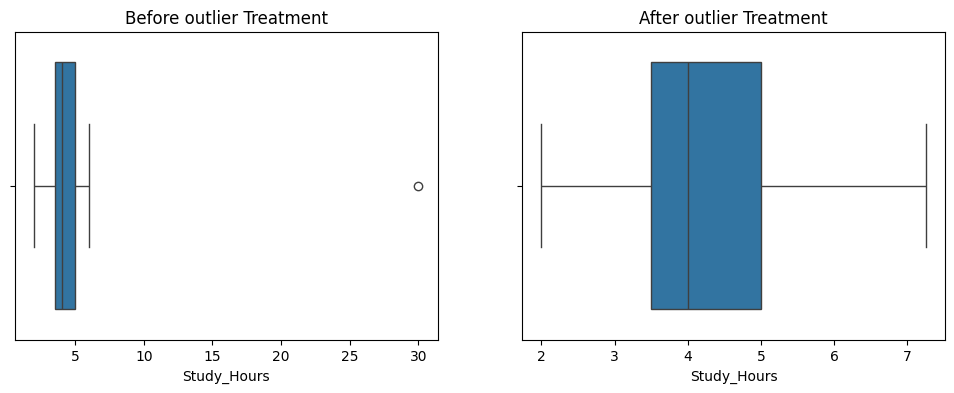

In [ ]:
plt.figure(figsize=(12,4))
plt.subplot(1,2,1)
sns.boxplot(x=df["Study_Hours"])
plt.title("Before outlier Treatment")
plt.subplot(1,2,2)
sns.boxplot(x=df_capped["Study_Hours"])
plt.title("After outlier Treatment")
plt.show()
